In [28]:
#cell1
from typing import TypedDict, Annotated
from langchain_core.messages import AnyMessage, HumanMessage
from langchain_core.tools import tool
from langgraph.graph.message import add_messages
from langchain_core.prompts import ChatPromptTemplate
from pydantic import BaseModel, Field

from langgraph.graph import StateGraph, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.sqlite import SqliteSaver

import sqlite3

In [29]:
#cell2
import getpass
from langchain_groq import ChatGroq

groq_api_key = getpass.getpass("Enter your Groq API key: ")

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    api_key=groq_api_key,
    max_retries=1
)

print("Groq initialized successfully!")

Groq initialized successfully!


In [44]:
#cell3
class TicketState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

    category: str
    urgency: str

    draft: str
    feedback: str

    attempts: int
    passed: bool

    approval_status: str
    approval_attempts: int

In [45]:
#cell4
@tool
def lookup_order(order_id: str) -> str:
    """Look up details of a customer's order."""

    return (
        f"Order {order_id}: "
        "Charged $50 twice due to a system glitch. "
        "Refund is required."
    )


billing_llm = llm.bind_tools([lookup_order])

print("Order lookup tool created!")

Order lookup tool created!


In [46]:
#cell5
class ClassificationOutput(BaseModel):
    category: str = Field(
        description="One of: billing, technical, general"
    )

    urgency: str = Field(
        description="One of: high, medium, low"
    )


def classify_ticket(state: TicketState):

    customer_message = state["messages"][-1].content

    prompt = f"""
    Classify this customer support ticket.

    Customer message: {customer_message}

    Category must be billing, technical, or general.
    Urgency must be high, medium, or low.
    """

    result = llm.with_structured_output(
        ClassificationOutput
    ).invoke(prompt)

    return {
        "category": result.category,
        "urgency": result.urgency,
        "attempts": 0,
        "feedback": "",
        "approval_attempts": 0
    }

In [47]:
def billing_handler(state: TicketState):

    customer_message = state["messages"][-1].content
    feedback = state.get("feedback", "")

    prompt = f"""
    You are a professional billing support agent.

    Customer message: {customer_message}
    Previous reviewer feedback: {feedback}

    Use the lookup_order tool to verify the order.
    """

    response = billing_llm.invoke(prompt)

    # Initialize before checking tool calls
    tool_results = []

    if response.tool_calls:
        for tool_call in response.tool_calls:

            if tool_call["name"] == "lookup_order":
                result = lookup_order.invoke(tool_call["args"])
                tool_results.append(result)

    if tool_results:
        final_prompt = f"""
        Customer message: {customer_message}
        Verified order details: {tool_results}

        Write a polite billing reply.
        Only mention verified facts.
        Do not invent refund timelines or contact details.
        Explain that the billing team will review the refund.
        """

        final_response = llm.invoke(final_prompt)
        draft = final_response.content

    else:
        draft = (
            "We are sorry for the inconvenience. "
            "Our billing team will investigate your issue."
        )

    return {"draft": draft}

In [48]:
#cell7
def technical_handler(state: TicketState):

    customer_message = state["messages"][-1].content
    feedback = state.get("feedback", "")

    prompt = f"""
    You are a technical support agent.

    Customer issue: {customer_message}

    Previous reviewer feedback: {feedback}

    Provide a clear and helpful solution in simple steps.
    """

    response = llm.invoke(prompt)

    return {"draft": response.content}

In [49]:
#cell8
def general_handler(state: TicketState):

    customer_message = state["messages"][-1].content
    feedback = state.get("feedback", "")

    prompt = f"""
    You are a customer support agent.

    Customer message: {customer_message}

    Previous reviewer feedback: {feedback}

    Write a polite and helpful response.
    """

    response = llm.invoke(prompt)

    return {"draft": response.content}

In [50]:
#cell9
class ReviewOutput(BaseModel):

    passed: bool = Field(
        description="Whether the draft is good enough to send"
    )

    feedback: str = Field(
        description="Suggestions to improve the draft"
    )


def reviewer(state: TicketState):

    draft = state["draft"]

    prompt = f"""
    You are a strict customer support quality reviewer.

    Review this reply:

    {draft}

    Check:
    1. Is it polite and professional?
    2. Is it relevant to the customer's problem?
    3. Is it clear and helpful?
    4. Does it avoid unsupported claims?

    If it satisfies all requirements, passed=True.
    Otherwise, passed=False and provide feedback.
    """

    result = llm.with_structured_output(
        ReviewOutput
    ).invoke(prompt)

    return {
        "passed": result.passed,
        "feedback": result.feedback,
        "attempts": state.get("attempts", 0) + 1
    }

In [51]:
#cell10
def human_approval(state: TicketState):

    decision = interrupt({
        "message": "Please review the customer reply.",

        "draft": state["draft"],

        "instruction": (
            "Approve using {'decision': 'approve'} "
            "or reject using "
            "{'decision': 'reject', 'feedback': 'Your feedback'}"
        )
    })

    if decision["decision"] == "approve":

        return {
            "approval_status": "approved"
        }

    return {
        "approval_status": "rejected",

        "passed": False,

        "feedback": decision.get(
            "feedback",
            "Human reviewer requested changes."
        ),

        "approval_attempts": (
            state.get("approval_attempts", 0) + 1
        )
    }

In [52]:
#cell11
def send_reply(state: TicketState):

    return {
        "messages": [
            ("assistant", state["draft"])
        ]
    }


def route_to_handler(state: TicketState):

    return state["category"]


def review_routing(state: TicketState):

    if state["passed"] or state["attempts"] >= 3:

        if state["category"] == "billing":
            return "human_approval"

        return "send_reply"

    return state["category"]


def route_after_human_approval(state: TicketState):

    if state["approval_status"] == "approved":
        return "send_reply"

    if state.get("approval_attempts", 0) < 2:
        return "billing_handler"

    return "stop"

In [39]:
#cell12
workflow = StateGraph(TicketState)

# Add nodes
workflow.add_node("classifier", classify_ticket)

workflow.add_node("billing_handler", billing_handler)

workflow.add_node("technical_handler", technical_handler)

workflow.add_node("general_handler", general_handler)

workflow.add_node("reviewer", reviewer)

workflow.add_node("human_approval", human_approval)

workflow.add_node("send_reply", send_reply)


# Entry point
workflow.set_entry_point("classifier")


# Classification routing
workflow.add_conditional_edges(
    "classifier",
    route_to_handler,
    {
        "billing": "billing_handler",
        "technical": "technical_handler",
        "general": "general_handler"
    }
)


# Handlers to reviewer
workflow.add_edge("billing_handler", "reviewer")

workflow.add_edge("technical_handler", "reviewer")

workflow.add_edge("general_handler", "reviewer")


# Reviewer routing
workflow.add_conditional_edges(
    "reviewer",
    review_routing,
    {
        "billing": "billing_handler",
        "technical": "technical_handler",
        "general": "general_handler",
        "human_approval": "human_approval",
        "send_reply": "send_reply"
    }
)


# Human approval routing
workflow.add_conditional_edges(
    "human_approval",
    route_after_human_approval,
    {
        "send_reply": "send_reply",
        "billing_handler": "billing_handler",
        "stop": END
    }
)


# Final node
workflow.add_edge("send_reply", END)

print("Workflow created successfully!")

Workflow created successfully!


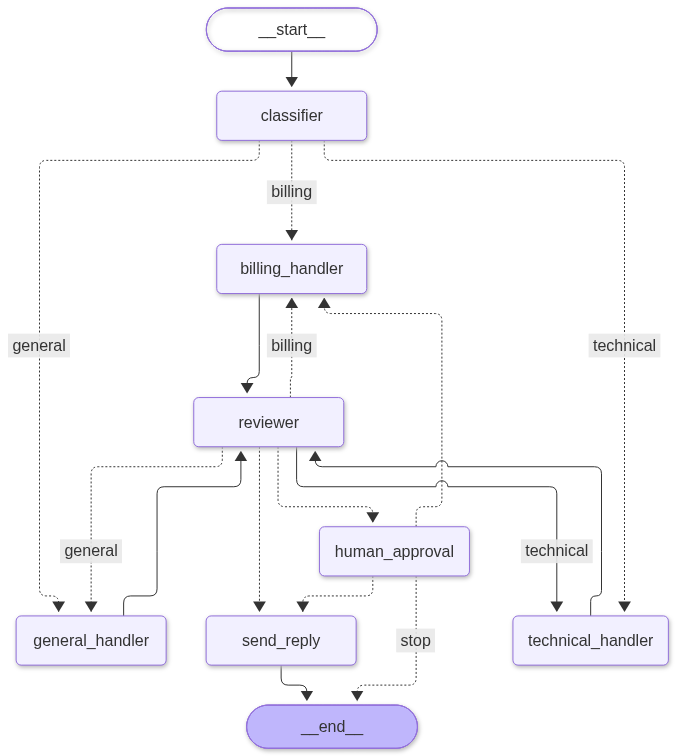

In [58]:
#cell13
from IPython.display import Image, display

display(
    Image(app.get_graph().draw_mermaid_png())
)

In [59]:
#cell14
technical_config = {
    "configurable": {
        "thread_id": "technical_final_001"
    }
}

technical_input = {
    "messages": [
        HumanMessage(
            content=(
                "My application keeps crashing "
                "whenever I try to log in."
            )
        )
    ]
}

result = app.invoke(
    technical_input,
    config=technical_config
)

print("CATEGORY:", result["category"])
print("URGENCY:", result["urgency"])
print("DRAFT:", result["draft"])
print("REVIEW PASSED:", result["passed"])
print("ATTEMPTS:", result["attempts"])

print("\nFINAL REPLY:")
print(result["messages"][-1].content)

CATEGORY: technical
URGENCY: high
DRAFT: **Quick‑Fix Checklist for “App Crashes on Login”**

1. **Restart the Device**  
   - Close the app completely (remove from recent‑apps list).  
   - Reboot your phone/computer.  
   - Open the app again and try logging in.

2. **Check for Updates**  
   - **Mobile:** Go to the App Store / Google Play → “My apps” → update the app if a newer version is available.  
   - **Desktop:** Open the app → Help → Check for updates (or visit the website for the latest installer).

3. **Clear Cache / Local Data**  
   - **Android:** Settings → Apps → [Your App] → Storage → Clear Cache (and Clear Data if the crash persists).  
   - **iOS:** Delete the app and reinstall it.  
   - **Windows/macOS:** Delete the app’s local data folder (usually in `AppData` or `Library/Application Support`).

4. **Verify Internet Connection**  
   - Switch between Wi‑Fi and mobile data (or Ethernet).  
   - Disable any VPN or proxy that might block the login request.

5. **Check

In [55]:
print(billing_handler.__code__.co_firstlineno)
test_state = {
    "messages": [
        HumanMessage(content="I was charged twice for order 1042.")
    ],
    "feedback": ""
}

test_result = billing_handler(test_state)
print(test_result)

1
{'draft': 'Thank you for letting us know about the duplicate charge on order\u202f1042. We see that the order was charged $50 twice due to a system glitch, and a refund is required. Our billing team will review the refund and take the necessary steps to correct the issue.'}


In [56]:
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

conn = sqlite3.connect(
    "tickets.sqlite",
    check_same_thread=False
)

memory = SqliteSaver(conn)

print("SQLite memory initialized successfully!")

SQLite memory initialized successfully!


In [57]:
app = workflow.compile(
    checkpointer=memory
)

print("New application compiled successfully!")

New application compiled successfully!


In [ ]:
billing_config = {
    "configurable": {
        "thread_id": "billing_reject_001"
    }
}

billing_input = {
    "messages": [
        HumanMessage(
            content="I was charged twice for order 1042. Please refund me."
        )
    ]
}

result = app.invoke(
    billing_input,
    config=billing_config
)

print("CATEGORY:", result["category"])
print("DRAFT:", result["draft"])

print("PENDING NODES:", app.get_state(billing_config).next)

CATEGORY: billing
DRAFT: Dear Customer,

Thank you for reaching out. We’ve reviewed your account and see that Order 1042 was charged $50 twice due to a system glitch. A refund is required.

Our billing team will review the refund request and take the necessary steps to correct the charge.

Thank you for your patience.
PENDING NODES: ('human_approval',)


In [ ]:
result = app.invoke(
    Command(resume={"decision": "approve"}),
    config=billing_config
)

print("FINAL APPROVED REPLY:")
print(result["messages"][-1].content)

print("\nWORKFLOW COMPLETED!")

FINAL APPROVED REPLY:
Dear Customer,

Thank you for reaching out. We’ve reviewed your account and see that Order 1042 was charged $50 twice due to a system glitch. A refund is required.

Our billing team will review the refund request and take the necessary steps to correct the charge.

Thank you for your patience.

WORKFLOW COMPLETED!


In [ ]:
snapshot = app.get_state(billing_config)

print("Remaining nodes:", snapshot.next)
print("Approval status:", snapshot.values["approval_status"])

Remaining nodes: ()
Approval status: approved


In [ ]:
reject_result = app.invoke(
    Command(
        resume={
            "decision": "reject",
            "feedback": (
                "Please make the response shorter "
                "and explain the refund process more clearly."
            )
        }
    ),
    config={
        "configurable": {
            "thread_id": "billing_reject_001"
        }
    }
)

print("Workflow state after rejection:")
print(app.get_state({
    "configurable": {
        "thread_id": "billing_reject_001"
    }
}).values)

Workflow state after rejection:
{'messages': [HumanMessage(content='I was charged twice for order 1042. Please refund me.', additional_kwargs={}, response_metadata={}, id='539713cb-34dd-4cb0-b088-07a4eeaa6e4e'), AIMessage(content='Dear Customer,\n\nThank you for reaching out. We’ve reviewed your account and see that Order\u202f1042 was charged $50 twice due to a system glitch. A refund is required.\n\nOur billing team will review the refund request and take the necessary steps to correct the charge.\n\nThank you for your patience.', additional_kwargs={}, response_metadata={}, id='0ece6431-cb19-4af7-ae96-745ce79cdf5e', tool_calls=[], invalid_tool_calls=[])], 'category': 'billing', 'urgency': 'high', 'draft': 'Dear Customer,\n\nThank you for reaching out. We’ve reviewed your account and see that Order\u202f1042 was charged $50 twice due to a system glitch. A refund is required.\n\nOur billing team will review the refund request and take the necessary steps to correct the charge.\n\nThank

In [ ]:
config = {
    "configurable": {
        "thread_id": "billing_reject_001"
    }
}

snapshot = app.get_state(config)

print("Pending nodes:", snapshot.next)
print("Approval status:", snapshot.values.get("approval_status"))
print("Feedback:", snapshot.values.get("feedback"))
print("Draft:", snapshot.values.get("draft"))

Pending nodes: ()
Approval status: approved
Feedback: The reply is polite, relevant, clear, and does not contain unsupported claims. It meets all the specified criteria.
Draft: Dear Customer,

Thank you for reaching out. We’ve reviewed your account and see that Order 1042 was charged $50 twice due to a system glitch. A refund is required.

Our billing team will review the refund request and take the necessary steps to correct the charge.

Thank you for your patience.


In [ ]:
config = {
    "configurable": {
        "thread_id": "billing_reject_001"
    }
}

snapshot = app.get_state(config)

print("Approval attempts:", snapshot.values.get("approval_attempts"))
print("Messages:", snapshot.values["messages"])

Approval attempts: 0
Messages: [HumanMessage(content='I was charged twice for order 1042. Please refund me.', additional_kwargs={}, response_metadata={}, id='539713cb-34dd-4cb0-b088-07a4eeaa6e4e'), AIMessage(content='Dear Customer,\n\nThank you for reaching out. We’ve reviewed your account and see that Order\u202f1042 was charged $50 twice due to a system glitch. A refund is required.\n\nOur billing team will review the refund request and take the necessary steps to correct the charge.\n\nThank you for your patience.', additional_kwargs={}, response_metadata={}, id='0ece6431-cb19-4af7-ae96-745ce79cdf5e', tool_calls=[], invalid_tool_calls=[])]


# Testing and Execution Results

The customer support workflow is tested using three types of queries:
1. General Query
2. Technical Query
3. Billing Query

Each test demonstrates ticket classification, urgency detection, response generation, and workflow execution.

In [ ]:
from langchain_core.messages import HumanMessage

In [60]:
general_config = {
    "configurable": {
        "thread_id": "general_test_001"
    }
}

general_input = {
    "messages": [
        HumanMessage(
            content="What are your customer support working hours?"
        )
    ]
}

general_result = app.invoke(
    general_input,
    config=general_config
)

print("GENERAL QUERY TEST")
print("Category:", general_result["category"])
print("Urgency:", general_result["urgency"])
print("Generated Reply:")
print(general_result["draft"])
print("Pending Nodes:", app.get_state(general_config).next)

GENERAL QUERY TEST
Category: general
Urgency: low
Generated Reply:
Hello!  

Thank you for reaching out. Our customer support team is available during the following hours (local time):

- **Monday – Friday:** 9:00 AM – 5:00 PM  
- **Saturday – Sunday:** Closed (you can still submit a ticket and we’ll get back to you on Monday)

If you need assistance outside of these hours, feel free to send us an email or submit a support ticket through our website. We’ll respond as soon as we’re back online.  

Let me know if there’s anything else I can help with!
Pending Nodes: ()


In [61]:
technical_config = {
    "configurable": {
        "thread_id": "technical_test_001"
    }
}

technical_input = {
    "messages": [
        HumanMessage(
            content="I am unable to log in to my account. "
                    "It keeps showing an incorrect password error."
        )
    ]
}

technical_result = app.invoke(
    technical_input,
    config=technical_config
)

print("TECHNICAL QUERY TEST")
print("Category:", technical_result["category"])
print("Urgency:", technical_result["urgency"])
print("Generated Reply:")
print(technical_result["draft"])
print("Pending Nodes:", app.get_state(technical_config).next)

TECHNICAL QUERY TEST
Category: technical
Urgency: high
Generated Reply:
**Hi there!**  
I’m sorry you’re having trouble logging in. Let’s get you back into your account with a few quick steps.

---

## 1. Double‑check the basics

| Step | What to do | Why it matters |
|------|------------|----------------|
| **1.1** | Make sure you’re typing the **exact** username/email you used when you signed up. | A typo can trigger a password‑error message. |
| **1.2** | Verify the **password**: <br>• Caps Lock is off.<br>• Num Lock is on (if you use numbers).<br>• No extra spaces before or after the password. | Even a single stray space will cause a mismatch. |
| **1.3** | Try the **same password** on a different device or browser (e.g., Chrome → Safari). | Rules out a browser‑specific glitch. |

---

## 2. Reset your password (if the above doesn’t work)

1. **Go to the login page** and click **“Forgot password?”**  
2. **Enter your email address** (the one linked to your account).  
3. **Check yo

In [62]:
billing_config = {
    "configurable": {
        "thread_id": "billing_test_001"
    }
}

billing_input = {
    "messages": [
        HumanMessage(
            content="I was charged twice for order 1042. "
                    "Please refund me."
        )
    ]
}

billing_result = app.invoke(
    billing_input,
    config=billing_config
)

print("BILLING QUERY TEST")
print("Category:", billing_result["category"])
print("Urgency:", billing_result["urgency"])
print("Generated Reply:")
print(billing_result["draft"])
print("Pending Nodes:", app.get_state(billing_config).next)

BILLING QUERY TEST
Category: billing
Urgency: high
Generated Reply:
Dear Customer,

Thank you for reaching out. We’ve reviewed your account and see that Order 1042 was charged $50 twice due to a system glitch. A refund is required.

Our billing team will review the refund request and take the necessary steps to correct the charge.

Thank you for your patience.
Pending Nodes: ('human_approval',)


In [63]:
billing_result = app.invoke(
    Command(resume={"decision": "approve"}),
    config=billing_config
)

print("FINAL APPROVED REPLY:")
print(billing_result["messages"][-1].content)

print("Workflow completed!")

FINAL APPROVED REPLY:
Dear Customer,

Thank you for reaching out. We’ve reviewed your account and see that Order 1042 was charged $50 twice due to a system glitch. A refund is required.

Our billing team will review the refund request and take the necessary steps to correct the charge.

Thank you for your patience.
Workflow completed!
